# Chapter 6. The regime gate

**Question.** Can the overall size of the book be set by recognising the
market's state, running smaller in regimes where the sleeve has
historically lost?

**Covers:**
1. how the gate works: features, k-means on an expanding window, learned
   multipliers;
2. the number of regimes, and the elbow rule ("auto-k");
3. WK-means, the clever alternative that lost, and why;
4. **the comparison error**: judging two books at different volatility;
5. the nested test over gate variants, and the decision.

**Configuration:** A-12, monthly, net, HRP on, Sharpe after the risk-free
rate, out of sample from 2008-09-04.

In [1]:
from _setup import *
from cta.walkforward import two_year_windows, nested
from cta.regime import _regime_features, _REGIME_CACHE

UNI = buckets(A12)
BASE = dict(MONTHLY, apply_costs=True, hrp=True, universe=UNI)
LEARN = dict(regime_gate=True, regime_mult_mode="learned")
TREND5 = ("vol", "corr", "er", "disp", "agree")
WINDOWS = two_year_windows(df.index, OOS)


def run(target=0.12, **kw):
    out = build_trend_nav(df, symbols=A12, **{**BASE, "base_target_vol": target, **kw})
    return returns(out[0])

## 1. How the gate works

Each day is described by five statistics of the whole book, all lagged a
day: volatility, average correlation between markets, the efficiency ratio
(trend quality), cross-sectional dispersion, and **agreement**, the share
of markets whose fast and slow legs point the same way.

k-means groups days into regimes on an EXPANDING window, refitting about
once a year; each new day is classified by the latest fit, never by a fit
that saw it. Each regime gets a multiplier on the portfolio volatility
target, from 1.0 down to 0.5.

**Learned, not assumed.** A long-only intuition says violent regimes are
the dangerous ones. For a trend follower that is backwards: by the time a
crash is recognisable the book is usually already short, so the "crisis"
cluster tends to PAY. The gate therefore ranks regimes by what the sleeve
actually earned over the following 21 days, counting only windows that had
closed before the decision date, and gives the best regime 1.0.

In [2]:
feats = _regime_features(df, A12)[list(TREND5)]
feats.loc[OOS:].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
vol,0.1268,0.0812,0.0426,0.7071
corr,0.0928,0.1195,-0.0533,1.0000
er,0.0380,0.0531,0.0000,0.3270
disp,0.0122,0.0063,0.0058,0.0552
agree,0.5936,0.2366,0.0000,1.0000


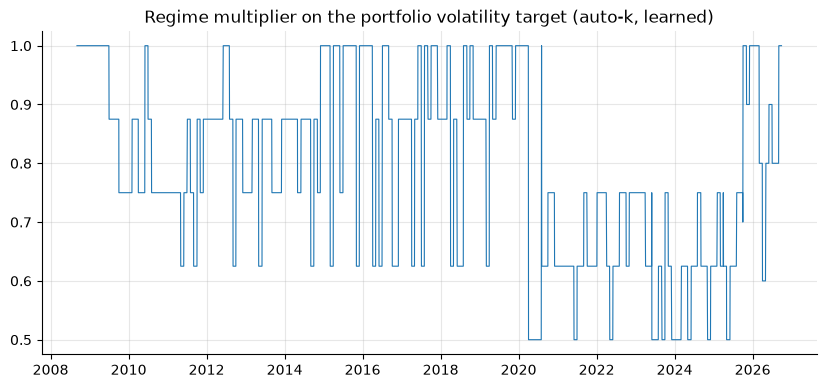

share of days at each multiplier:
0.5000   0.0690
0.6000   0.0050
0.6200   0.2290
0.7000   0.0000
0.7500   0.2080
0.8000   0.0190
0.8800   0.2310
0.9000   0.0090
1.0000   0.2300


In [3]:
gate = run(**LEARN, regime_features=TREND5, regime_auto_k=(2, 10))
mult = list(_REGIME_CACHE.values())[-1]
fig, ax = plt.subplots()
ax.plot(mult.loc[OOS:], lw=0.8)
ax.set_title("Regime multiplier on the portfolio volatility target (auto-k, learned)")
plt.show()
print("share of days at each multiplier:")
print(mult.loc[OOS:].round(2).value_counts(normalize=True).sort_index().round(3).to_string())

## 2. How many regimes? The elbow rule

The first version fixed k = 3, inherited from a proposal and never tested.
The elbow rule chooses k at every refit from the shape of the clustering
alone: fit k = 2..10, draw a line from the first point of the inertia curve
to the last, take the k furthest below it. No return, Sharpe or drawdown
enters the choice, so it cannot be tuned to performance.

In [4]:
rows = {"no gate": run()}
for k in (2, 3, 5, 7):
    rows[f"k={k}"] = run(**LEARN, regime_features=TREND5, regime_clusters=k)
rows["auto-k"] = gate
describe(rows, stacked=True)

,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
no gate,0.5043,0.1389,0.0795,-0.3122,0.7651,0.1947,-0.3316
k=2,0.4296,0.1220,0.0625,-0.3122,0.7268,0.1766,-0.3316
k=3,0.4772,0.1097,0.0640,-0.2456,0.7511,0.1787,-0.3160
k=5,0.4242,0.1130,0.0588,-0.2512,0.7291,0.1732,-0.3316
k=7,0.4728,0.1183,0.0668,-0.2677,0.7511,0.1817,-0.3316
auto-k,0.4285,0.1139,0.0596,-0.2512,0.7305,0.1740,-0.3316


The same pattern at every k: the gate cuts the sleeve's worst loss, and
at a common 12% target its Sharpe is lower at every k (section 4 explains
why a common target is the wrong comparison). A
single fixed k that happens to look best (k=7 did, in the original run) is
one value out of seven tried: a cherry pick. The best fixed k measured
window by window moved between several values, so no fixed choice was ever
available in advance; auto-k removes the guess.

## 3. WK-means: better labels, worse trading

Wasserstein k-means (Horvath, Issa and Muguruza, 2021) clusters the whole
return DISTRIBUTION of each window instead of hand-picked features.
Nothing is hand-picked; volatility, skew and tails all enter. It produced
the most credible regime labels of any method tried.

In [5]:
wk = run(**LEARN, regime_method="wasserstein")
describe({"no gate": rows["no gate"], "feature k-means, auto-k": gate,
          "WK-means": wk}, stacked=True)

,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
no gate,0.5043,0.1389,0.0795,-0.3122,0.7651,0.1947,-0.3316
"feature k-means, auto-k",0.4285,0.1139,0.0596,-0.2512,0.7305,0.1740,-0.3316
WK-means,0.4789,0.1030,0.0615,-0.2663,0.7411,0.1754,-0.3384


Against no gate it loses, and it is the only variant that deepens the
STACKED book's worst loss: it cuts risk at the moments the sleeve should be
cushioning the equity position. (On A-12 it happens to score above the
feature gate on Sharpe; on A-13, where the decision was made, it was worse
on every measure.) The reason it cuts at the wrong moments is structural.
WK-means represents a window as a sorted list of returns. Sorting is exactly what makes the distance cheap,
and sorting **destroys time order**:

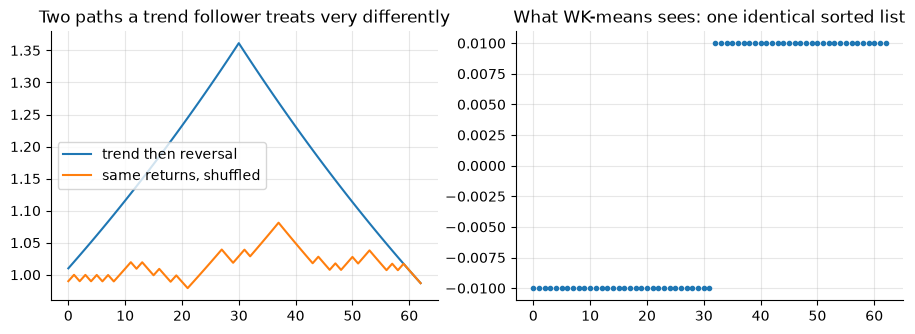

WK-means distance between the two windows: 0.0


In [6]:
rng = np.random.default_rng(1)
up = np.r_[np.full(31, 0.01), np.full(32, -0.01)]          # a clean rise, then a clean fall
shuffled = rng.permutation(up)                               # the same days, as noise
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(np.cumprod(1 + up), label="trend then reversal")
ax[0].plot(np.cumprod(1 + shuffled), label="same returns, shuffled"); ax[0].legend()
ax[0].set_title("Two paths a trend follower treats very differently")
ax[1].plot(np.sort(up), "o", ms=3); ax[1].set_title("What WK-means sees: one identical sorted list")
plt.show()
print("WK-means distance between the two windows:", float(np.abs(np.sort(up) - np.sort(shuffled)).mean()))

The feature that does most of the work in the feature-based gate,
agreement between the fast and slow legs, is a path statistic, and so is
the efficiency ratio. A distribution-based method cannot see either.

## 4. The comparison error

At a common 12% target, the gate looked like it cost return. That
conclusion stood for a day. The gate runs the book SMALLER, and scaling a
strategy up or down does not change its return per unit of risk. Two books
at different volatility cannot be compared directly.

In [7]:
pair = {"no gate, 12%": rows["no gate"], "gate, 12%": gate}
t = describe(pair)
print(t[["vol", "cagr", "max_dd"]])
scaled = matched(gate, vol(oos(rows["no gate"])))
describe({"no gate, 12%": rows["no gate"], "gate, scaled to the same realised vol": scaled})

                vol   cagr  max_dd
no gate, 12% 0.1389 0.0795 -0.3122
gate, 12%    0.1139 0.0596 -0.2512


,sharpe,vol,cagr,max_dd
"no gate, 12%",0.5043,0.1389,0.0795,-0.3122
"gate, scaled to the same realised vol",0.4528,0.1418,0.0725,-0.3038


Scaling to the same realised risk removes most of the apparent cost:
comparing at different volatility had made the gate look far worse than it
is. To compare properly across the whole defensible range, run both at
targets from 12% to 18% and plot return against drawdown.

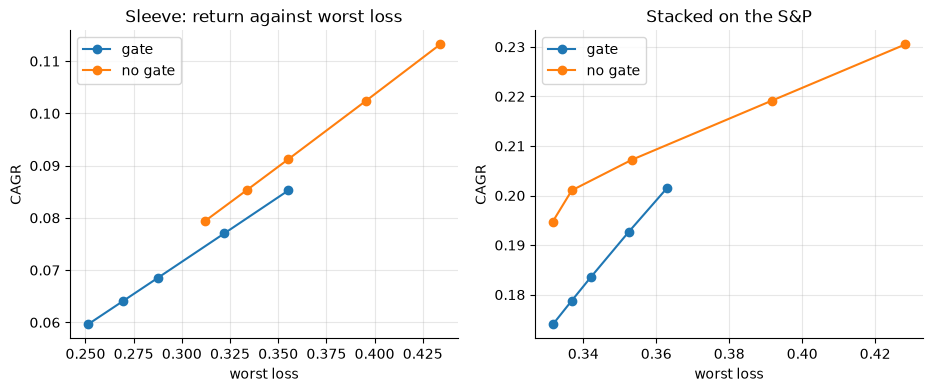

,,vol,cagr,max_dd,stacked_cagr,stacked_dd
gate,target,,,,,
no gate,0.1200,0.1389,0.0795,-0.3122,0.1947,-0.3316
gate,0.1200,0.1139,0.0596,-0.2512,0.1740,-0.3316
no gate,0.1300,0.1505,0.0854,-0.3340,0.2010,-0.3368
gate,0.1300,0.1234,0.0641,-0.2695,0.1788,-0.3368
no gate,0.1400,0.1621,0.0912,-0.3551,0.2072,-0.3533
gate,0.1400,0.1329,0.0685,-0.2874,0.1835,-0.3421
no gate,0.1600,0.1853,0.1024,-0.3957,0.2191,-0.3916
gate,0.1600,0.1518,0.0770,-0.3221,0.1927,-0.3525
no gate,0.1800,0.2084,0.1132,-0.4340,0.2305,-0.4282


In [8]:
front = []
for tv in (0.12, 0.13, 0.14, 0.16, 0.18):
    for label, kw in (("no gate", {}), ("gate", dict(LEARN, regime_features=TREND5, regime_auto_k=(2, 10)))):
        r = run(target=tv, **kw)
        front.append(dict(gate=label, target=tv, vol=vol(oos(r)), cagr=cagr(oos(r)),
                          max_dd=max_drawdown(oos(r)),
                          stacked_cagr=cagr(oos(r + SPX)), stacked_dd=max_drawdown(oos(r + SPX))))
front = pd.DataFrame(front)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for g, sub in front.groupby("gate"):
    ax[0].plot(-sub.max_dd, sub.cagr, "o-", label=g)
    ax[1].plot(-sub.stacked_dd, sub.stacked_cagr, "o-", label=g)
ax[0].set_title("Sleeve: return against worst loss"); ax[1].set_title("Stacked on the S&P")
for a in ax:
    a.set_xlabel("worst loss"); a.set_ylabel("CAGR"); a.legend()
plt.show()
front.set_index(["gate", "target"])

On A-12, today, the two frontiers cross: the gate gives a shallower sleeve
drawdown, but at the same realised risk it earns less, and the stacked
book barely benefits.

**That is not what the decision was based on.** The gate was chosen on
11 September on A-13, the same markets plus the Gilt. Re-running the same
matched-volatility test on both universes shows what changed:

In [9]:
A13 = sorted(A12 + ["gilt"])
rows13 = []
for name, syms in (("A-13 (with the Gilt)", A13), ("A-12 (without)", A12)):
    kw = dict(MONTHLY, apply_costs=True, hrp=True, universe=buckets(syms))
    ng = returns(build_trend_nav(df, symbols=syms, **kw)[0])
    g = returns(build_trend_nav(df, symbols=syms, **{**kw, **GATE, "base_target_vol": 0.13, "hrp_lag": 1})[0])
    gm = matched(oos(g), vol(oos(ng)))
    rows13.append(dict(universe=name, no_gate_sharpe=sharpe(oos(ng), RF), gate_sharpe=sharpe(oos(g), RF),
                       cagr_gain_at_matched_vol=cagr(gm) - cagr(oos(ng)),
                       dd_gain_at_matched_vol=max_drawdown(gm) - max_drawdown(oos(ng))))
pd.DataFrame(rows13).set_index("universe")

,no_gate_sharpe,gate_sharpe,cagr_gain_at_matched_vol,dd_gain_at_matched_vol
universe,,,,
A-13 (with the Gilt),0.4673,0.4767,0.0021,0.0329
A-12 (without),0.5043,0.4349,-0.0085,0.0119


On A-13 the gate wins at matched risk on both return and drawdown, which
reproduces the original decision. On A-12 it does not. Removing one bond
market, the only other fixed-income market besides the US 10-year, changed
the verdict, and the gate was never re-tested when the Gilt was dropped on
24 September. Two things follow:

* The gate stays in the live configuration, because the project's rule is
  not to tune it on past performance, and because with crypto in the book
  it helps again (Chapter 8).
* It is a clear open item: the gate's justification rests on a universe
  the live book no longer trades.

Either way it is insurance, not an engine: where it helps, the benefit
comes from a few crisis windows.

## 5. Can the gate be tuned? The nested test

Ten plausible gate variants (feature sets, fixed or auto k, forward
windows, WK-means). Choose among them on training data only, judge on the
next window, chain.

In [10]:
ORIG, RICH = ("vol", "corr", "er"), ("vol", "corr", "er", "dist_ma", "dd", "vol_ratio",
                                    "chg", "disp", "agree", "rsi")
CANDIDATES = {
    "orig3 k=3": dict(**LEARN, regime_features=ORIG),
    "orig3 auto-k": dict(**LEARN, regime_features=ORIG, regime_auto_k=(2, 10)),
    "trend5 k=3": dict(**LEARN, regime_features=TREND5),
    "trend5 auto-k": dict(**LEARN, regime_features=TREND5, regime_auto_k=(2, 10)),
    "rich10 auto-k": dict(**LEARN, regime_features=RICH, regime_auto_k=(2, 10)),
    "min2 auto-k": dict(**LEARN, regime_features=("vol", "agree"), regime_auto_k=(2, 10)),
    "path3 auto-k": dict(**LEARN, regime_features=("er", "agree", "chg"), regime_auto_k=(2, 10)),
    "trend5 auto-k fwd10": dict(**LEARN, regime_features=TREND5, regime_auto_k=(2, 10), regime_fwd_window=10),
    "trend5 auto-k fwd42": dict(**LEARN, regime_features=TREND5, regime_auto_k=(2, 10), regime_fwd_window=42),
    "wasserstein k=3": dict(**LEARN, regime_method="wasserstein"),
}
cand = {k: run(**v) for k, v in CANDIDATES.items()}
picks, chain, _ = nested(cand, WINDOWS, OOS, rf=RF)
nogate_chain = pd.concat([rows["no gate"].loc[a:b] for a, b in WINDOWS])
nogate_chain = nogate_chain[~nogate_chain.index.duplicated()]
print("chosen per window:", picks["chose"].tolist())
pd.DataFrame({"gate chosen per window": stats(chain, RF), "no gate": stats(nogate_chain, RF)}).T

chosen per window: ['orig3 k=3', 'orig3 auto-k', 'orig3 k=3', 'orig3 auto-k', 'path3 auto-k', 'min2 auto-k', 'rich10 auto-k', 'min2 auto-k', 'min2 auto-k']


,sharpe,vol,cagr,max_dd
gate chosen per window,0.3222,0.1105,0.0459,-0.2563
no gate,0.4464,0.1378,0.0703,-0.3122


Choosing among gate variants on past performance does worse than running
no gate at all (originally 0.345 against 0.410). The variant that looks
best with hindsight cannot be picked in advance, and trying costs more than
the gate is worth.

**Decision (11 September, on A-13):** one variant, fixed a priori for its
drawdown behaviour (five features, auto-k, learned ranking), never tuned. The live engine
also uses a portable k-means (k-means++ on a small xorshift generator that
MQL5 can reproduce exactly) and a one-day HRP lag; together they move the
Sharpe by 0.0002.

In [11]:
describe({"no gate, 12%": rows["no gate"], "chosen: gate, 13%, portable": chosen()}, stacked=True)

,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
"no gate, 12%",0.5043,0.1389,0.0795,-0.3122,0.7651,0.1947,-0.3316
"chosen: gate, 13%, portable",0.4349,0.1225,0.0634,-0.2693,0.7357,0.1781,-0.3370
